# First cosmological analysis: inferring $\sigma_8$ from galaxy auto and galaxy x cmb lensing

- The first and second CoLoRe simulation boxes were generated by Laura Casas, Dani L. Jarque run the rest from then on.
- The notebook uses the sources output from CoLoRe, i.e. quasars, to validate the simulation through the auto-spectrum and cross spectrum with CMB lensing.
    - The kappa map (`out_kappa_z000.fits`) can be found in `./data/x_test_box/cmb_lensing/`, along with $C_{\ell}^{\kappa \kappa}$, the corresponding errorbars, and a logarithmic rebinning run with `./scripts/generate_rebinned_cls.py`.
    - The QSO catalogs (`out_srcs_sx_xx.fits`) can be found in `./data/x_test_box/desi_qso)/`, along with $C_{\ell}^{qq}$, the corresponding errorbars, and a logarithmic rebinning run with `./scripts/generate_rebinned_cls.py`.
    - The kappa $\times$ QSO spectrum $C_{\ell}^{\kappa q}$ can be found in `./data/x_test_box/desi_qso/` with the corresponding errorbars, and a logarithmic rebinning run with `./scripts/generate_rebinned_cls.py`.
- The notebook also fits for two parameter in the modelling accounting for CoLoRe finite cell size and a rescaling of the theory bias.

In [54]:
import numpy as np
import matplotlib.pyplot as plt
import camb
import healpy as hp

from scipy.optimize import minimize
from scipy.interpolate import PchipInterpolator
from scipy.integrate import simpson
from scipy.constants import c
import zeus, corner
import sys
sys.path.append('../')

from utils.rebinning import hybrid_bin_cls
import json

# functions

## theory

In [55]:
def load_cosmology(filename):
    with open(filename) as f:
        return json.load(f)

In [56]:
def get_camb_results(
    cosmo_dict,
    z_pk,
    kmax=100.0,
    lmax=2500,
    nonlinear=False,
):
    """
    Read a cosmological parameter dictionary, extract cosmological parameters,
    and build CAMB results instance
    """

    # Convert to CAMB inputs

    H0 = 100.0 * cosmo_dict["h"]
    ombh2 = cosmo_dict["omega_B"] * cosmo_dict["h"]**2
    omch2 = (cosmo_dict["omega_M"] - cosmo_dict["omega_B"]) * cosmo_dict["h"]**2

    # Initial CAMB params

    pars = camb.CAMBparams()
    pars.set_cosmology(
        H0=H0,
        ombh2=ombh2,
        omch2=omch2,
    )
    pars.set_dark_energy(w=cosmo_dict["w"])
    pars.InitPower.set_params(
        ns=cosmo_dict["ns"],
        As=cosmo_dict["As"]
    )

    # Matter power settings

    pars.set_matter_power(
        redshifts=z_pk,
        kmax=kmax
    )

    # note that to get CAMB's internal calculation accurate at the 1% level at L~2000,
    # need lens_potential_accuracy=2. Increase to 4 for accurate match to the Limber calculation here
    if nonlinear:
        pars.NonLinear = camb.model.NonLinear_pk
        pars.set_for_lmax(lmax=lmax, lens_potential_accuracy=4, nonlinear=True)
    else:
        pars.set_for_lmax(lmax=lmax, lens_potential_accuracy=4, nonlinear=False)

    # Final results
    results = camb.get_results(pars)

    return results

In [57]:
def W_g(z, kernel_context, kernel_args):
    '''
    Galaxy clustering kernel.
    '''

    # jacobian of transforming n(chi)=dN/dchi to n(z)=dN/dz, i.e. dchi/dz 
    c_kms = c * 1e-3
    Hz = kernel_context["Hz"]

    bz_interp = kernel_args["bz_interp"]
    nz_interp = kernel_args["nz_interp"]

    bias = bz_interp(z)
    ndensity = nz_interp(z)

    return bias * ndensity * (Hz / c_kms)

In [58]:
def W_kappa(z, kernel_context, kernel_args):
    '''
    CMB lensing convergence kernel.
    '''

    # geometry
    a = 1.0 / (1.0 + z)

    # comoving distance to lens and source
    chi = kernel_context["chi"]
    chi_source = kernel_context["chi_source"]

    # cosmological parameters
    H0, om = kernel_context["cosmo_params"]
    c_kms = c * 1e-3

    # kernel prefactor
    W_prefactor = 1.5 * (H0 / c_kms)**2 * om * (chi_source - chi) / chi_source
    W_geom = chi / a

    return W_prefactor * W_geom

## data

In [59]:
def get_colore_cls(box_filename):
    '''
    Load the Colore kappa power spectrum from a text file
    '''

    # load the data from the .npz file
    data = np.load(box_filename)
    ells, cl, err = data['ells'], data['cls'], data['err']

    return ells, cl, err

## fitting

In [60]:
def get_limber_cls_fit(
    params,
    z_grid,
    pk_interp_lin,
    kernel1_grid,
    kernel2_grid,
    kernel_context,
    pixwin1,
    pixwin2,
    lmin_fit,
    lmax_fit,
    sigma8_fid,
    kmax=100,
):
    '''
    Compute the angular qq/kq power spectra using the Limber approximation.
    '''

    # fitting parameters
    sigma8, kp, A_bias = params

    # multipoles and cls
    ells = np.arange(lmin_fit, lmax_fit + 1)
    cls_gg = np.zeros_like(ells, dtype=np.float64)
    cls_kg = np.zeros_like(ells, dtype=np.float64)

    # geometry
    chi = kernel_context["chi"][:, None]        # (Nz,1)
    Hz = kernel_context["Hz"][:, None]          # (Nz,1)
    c_kms = c * 1e-3

    # Limber k-grid (Nz, Nell)
    k = (ells[None, :] + 0.5) / chi

    # valid CAMB region
    mask = (k > 1e-4) & (k < kmax)

    # evaluate P(k,z) for all z and ell
    pk = np.zeros_like(k)
    pk[mask] = pk_interp_lin.P(
        np.broadcast_to(z_grid[:, None], k.shape)[mask],
        k[mask],
        grid=False,
    )

    # parameter-dependent smoothing
    smooth = np.exp(-(k / kp) ** 2)

    # full integrand
    base_gg = (c_kms / Hz) * (kernel1_grid[:, None] * kernel1_grid[:, None]) / chi**2
    base_kg = (c_kms / Hz) * (kernel1_grid[:, None] * kernel2_grid[:, None]) / chi**2
    integrand_gg = base_gg * pk * smooth
    integrand_kg = base_kg * pk * smooth

    # integrate all multipoles simultaneously
    cls_gg = A_bias**2 * (sigma8/sigma8_fid)**2 * simpson(
        integrand_gg,
        x=z_grid,
        axis=0,
    )

    cls_kg = A_bias * (sigma8/sigma8_fid)**2 * simpson(
        integrand_kg,
        x=z_grid,
        axis=0,
    )
    
    # match the healpix pixel window function with length of cls
    lmax_map1 = len(pixwin1) - 1
    lmax_map2 = len(pixwin2) - 1
    lmax_min = np.min([lmax_map1, lmax_map2, lmax_fit])
    pixwin1 = pixwin1[lmin_fit : (lmax_min + 1)]
    pixwin2 = pixwin2[lmin_fit : (lmax_min + 1)]
    ells = ells[:(lmax_min + 1 - lmin_fit)]
    cls_gg = cls_gg[:(lmax_min + 1 - lmin_fit)]
    cls_kg = cls_kg[:(lmax_min + 1 - lmin_fit)]
    cls_gg_smoothed = cls_gg * pixwin1 * pixwin1
    cls_kg_smoothed = cls_kg * pixwin1 * pixwin2

    return {
        "ells": ells,
        "cls_gg": cls_gg_smoothed,
        "cls_kg": cls_kg_smoothed,
    }

In [61]:
def get_chi2(
    params,
    z_grid,
    lmin_fit,
    lmax_fit,
    nbins_fit,
    pk_interp_lin,
    kernel1_grid,
    kernel2_grid,
    kernel_context,
    pixwin1,
    pixwin2,
    cls_data,
    cov_mat,
    sigma8_fid,
    kmax=100.0,
):
    '''
    Reduced chi-squared for gg and gk fitting.
    '''

    # compute theory
    results = get_limber_cls_fit(
        params,
        z_grid,
        pk_interp_lin,
        kernel1_grid,
        kernel2_grid,
        kernel_context,
        pixwin1,
        pixwin2,
        lmin_fit,
        lmax_fit,
        sigma8_fid,
        kmax=kmax,
    )

    # rebin theory
    _, cls_theory_gg, _ = hybrid_bin_cls(
        results["ells"],
        results["cls_gg"],
        nbins=nbins_fit,
        ell_min=lmin_fit,
        ell_max=lmax_fit,
    )

    _, cls_theory_kg, _ = hybrid_bin_cls(
        results["ells"],
        results["cls_kg"],
        nbins=nbins_fit,
        ell_min=lmin_fit,
        ell_max=lmax_fit,
    )

    # create theory vector
    cls_theory = np.concatenate((cls_theory_gg, cls_theory_kg))

    # remove invalid values
    mask = np.isfinite(cls_data)
    cls_data = cls_data[mask]
    cls_theory = cls_theory[mask]

    # get chi2 statistic
    invcov_mat = np.linalg.inv(cov_mat)
    chi2 = (cls_data - cls_theory) @ invcov_mat @ (cls_data - cls_theory).T
    
    return chi2 / (nbins_fit - 3)  # fitting 3 parameters

## sampler

In [62]:
def log_prior(theta):
    '''
    Flat priors on kp and A_bias.
    '''

    sigma8, kp, Abias = theta

    if 0 < sigma8 and 0.1 < kp < 2.0 and 0.5 < Abias < 1.5:
        return 0.0

    return -np.inf

In [63]:
def log_posterior(
    theta,
    z_grid,
    lmin_fit,
    lmax_fit,
    nbins_fit,
    pk_interp_lin,
    kernel1_grid,
    kernel2_grid,
    kernel_context,
    pixwin1,
    pixwin2,
    cls_data,
    cov_data,
    sigma8_fid,
    kmax=100.0,
):

    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf

    chi2_red = get_chi2(
        theta,
        z_grid,
        lmin_fit,
        lmax_fit,
        nbins_fit,
        pk_interp_lin,
        kernel1_grid,
        kernel2_grid,
        kernel_context,
        pixwin1,
        pixwin2,
        cls_data,
        cov_data,
        sigma8_fid,
        kmax)

    # recover total chi2
    ndof = nbins_fit - 3
    chi2 = chi2_red * ndof

    return lp - 0.5 * chi2

# Fitting sample

## boltzmann parameters

In [64]:
# set the redshift range for the boltzmann solver
zmin, zmax = 0, 1100
nz = 200
z_pk = zmin + np.exp(np.log(zmax - zmin + 1)*np.linspace(0, 1, nz)) - 1
z_pk = z_pk[::-1] # reverse to have higher redshift first for better interpolation at high z
lmin, lmax = 2, 2500

## measure and compare output n(z)

In [65]:
# choose the box for which to compare the theory and the CoLoRe Cls
box = 'fourth_test_box'  # options: 'third_test_box', 'fourth_test_box'
galaxy_catalog = 'lsst_gal'  # options: 'desi_bgs, 'desi_lrg', 'desi_qso', 'lsst_gal'

# get the limber cls for the last box
nside_g = 512  # this nside has to match the one used to generate the colore Cls in the script
nside_k = 512  # this nside has to match the one used to generate the colore Cls in the script
params_path = f'../data/{box}/cosmo_params.json'

In [66]:
# load the galaxy catalogs, galaxy bias and redshift distribution, 
z_bz, bz = np.loadtxt(f'../data/colore_files/bz/bz_{galaxy_catalog}.txt', unpack=True)
z_nz_input, nz_input = np.loadtxt(f'../data/colore_files/nz/nz_{galaxy_catalog}.txt', unpack=True)
zbin_width_input = np.diff(z_nz_input)[0]

# load the n(z) histogram output from colore
z_edges, nz_output = np.load(f'../data/{box}/cls/nz_hist_{galaxy_catalog}.npz')['z_edges'], np.load(f'../data/{box}/cls/nz_hist_{galaxy_catalog}.npz')['nz']
zbin_width_output = np.diff(z_edges)[0]

# create n(z) interpolator for the input galaxy bias and redshift distribution
fsky = (4 * np.pi) * (180 / np.pi)**2  # multiply by the total sky area in deg**2 and redshift bin width
nz_input = nz_input * fsky * zbin_width_output
norm = simpson(nz_input, z_nz_input)
nz_interp_input = PchipInterpolator(z_nz_input, nz_input, extrapolate=False)
bz_interp = PchipInterpolator(z_bz, bz, extrapolate=False)

In [67]:
# full redshift range for interpolation plot
zmin = 0.0
zmax = 3.8
z = np.linspace(zmin, zmax, 1000)

# create n(z) interpolator for the output redshift distributions
z_nz_output = 0.5*(z_edges[:-1] + z_edges[1:])  # get the bins middle points
z_nz_output = np.concatenate(([zmin], z_nz_output, [zmax]))  # add the first and last bin edges to the middle points redshift
z_nz_output_min = nz_input[0]
z_nz_output_max = nz_input[np.abs(z_nz_input - 3.8).argmin()]

nz_output = np.concatenate(([z_nz_output_min], nz_output, [z_nz_output_max]))  # add the first and last bin edges to the middle points n(z)
nz_interp_output = PchipInterpolator(z_nz_output, nz_output, extrapolate=True)

In [68]:
# define the redshift tomographic bin of the analysis
zmin_bin = 0.0
zmax_bin = 3.8
zbin = np.linspace(zmin_bin, zmax_bin, 1000)
nz_output_bin = nz_output.copy()
nz_output_bin[(z_nz_output <= zmin_bin) | (z_nz_output >= zmax_bin)] = 0  # ensure the interpolator is zero outside the tomographic bin

# create n(z) interpolator for the tomographic bin output redshift distributions
norm = simpson(nz_interp_output(zbin), zbin)
nz_interp_output_bin = PchipInterpolator(z_nz_output, nz_output_bin/norm, extrapolate=True)

/tmp/ipykernel_11373/544734809.py:16: RuntimeWarning: divide by zero encountered in divide
  ratio = (nz_interp_output_bin(z)*norm - (nz_interp_input(z))) / nz_interp_input(z)
/tmp/ipykernel_11373/544734809.py:16: RuntimeWarning: invalid value encountered in divide
  ratio = (nz_interp_output_bin(z)*norm - (nz_interp_input(z))) / nz_interp_input(z)


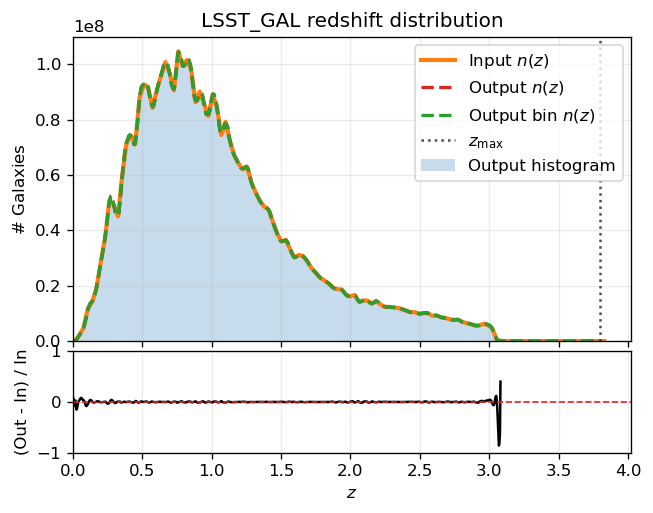

In [69]:
nbins = 400
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 4.5), dpi=120, sharex=True, gridspec_kw={'height_ratios':[3,1], 'hspace':0.05})

# Top panel
ax1.bar(z_nz_output, nz_output, width=zbin_width_output, align='center', color='C0', alpha=0.25, label='Output histogram')  # align=edge is needed to match the histogram bins edges with the bars edges
ax1.plot(z_nz_input, nz_interp_input(z_nz_input), 'C1', lw=2.5, label=r'Input $n(z)$')
ax1.plot(z, nz_interp_output(z), 'C3--', lw=2, label=r'Output $n(z)$')
ax1.plot(z, nz_interp_output_bin(z)*norm, 'C2--', lw=2, label=r'Output bin $n(z)$')
ax1.axvline(3.8, color='0.3', ls=':', lw=1.5, label=r'$z_{\rm max}$')
ax1.set_ylabel(r'$\#$ Galaxies')
ax1.set_title(f'{galaxy_catalog.upper()} redshift distribution')
ax1.legend(frameon=True)
ax1.grid(alpha=0.25)

# Bottom panel
ratio = (nz_interp_output_bin(z)*norm - (nz_interp_input(z))) / nz_interp_input(z)
ratio[(nz_interp_input(z) == 0)] = np.nan # set to nan if nz_output is zero
ratio[(nz_interp_output_bin(z) == 0)] = np.nan # set to nan if nz_output is zero
ax2.plot(z, ratio, 'k', lw=1.5)
ax2.axhline(0, color='C3', ls='--', lw=1)
ax2.set_xlim(left=0)
ax2.set_ylim(-1, 1)
ax2.set_xlabel(r'$z$')
ax2.set_ylabel('(Out - In) / In')
ax2.grid(alpha=0.25)

plt.show()

# First analysis: $\sigma_8$ fit

The plan is to infer $\sigma_8$ by breaking the degeneracy with galaxy bias $b(z)$ by combining galaxy auto and galaxy x cmb lensing spectrums. Marginalizing over $A_{bias}$ and $k_p$.

## preparation

In [70]:
# get cosmological parameters
cosmo_dict = load_cosmology(params_path)
z_max = cosmo_dict["z_max"]
sigma8_fid = cosmo_dict['sigma_8']

# get CAMB results
results_lin = get_camb_results(
    cosmo_dict=cosmo_dict,
    z_pk=z_pk,
    kmax=100,
    lmax=lmax,
    nonlinear=False
)

# get matter power spectrum interpolator
pk_interp_lin = results_lin.get_matter_power_interpolator(
    nonlinear=False,
    hubble_units=False,
    k_hunit=False,
    var1='delta_tot',
    var2='delta_tot'
)

z_star = cosmo_dict["z_out"]
chi_star = results_lin.comoving_radial_distance(z_star)


# cosmological parameters needed by kernels
H0 = cosmo_dict["h"] * 100
om = cosmo_dict["omega_M"]

# shared kernel context
chi_source = chi_star
kernel_context = {
    "results": results_lin,
    "chi_source": chi_source,
    "cosmo_params": (H0, om),
}

# precompute the z, chi(z) and H(z) grids for Limber integrand
z_grid = np.linspace(1e-4, z_max, 1000)
chi_grid = results_lin.comoving_radial_distance(z_grid)
Hz_grid = results_lin.hubble_parameter(z_grid)

# add to kernel context for use in kernels and Limber integrand
kernel_context["chi"] = chi_grid
kernel_context["Hz"] = Hz_grid

# defined the kernel arguments 
kernel1_args={
            "bz_interp": bz_interp,
            "nz_interp": nz_interp_output_bin}
kernel2_args=kernel1_args.copy()

# precompute the kernel grids for Limber integrand
Wk_grid = W_kappa(z_grid, kernel_context, kernel1_args)
Wg_grid = W_g(z_grid, kernel_context, kernel2_args)

In [71]:
# set the fitting range for the chi2 minimization
lmin_fit = 20
lmax_fit = 1000
nbins_fit = 30

# smooth with healpix pixel window function
pixwin_g = hp.pixwin(nside_g)
pixwin_k = hp.pixwin(nside_k)

In [72]:
# load and rebin gg data
box_path_gg = f'../data/{box}/cls/cl_gg_{galaxy_catalog}.npz'
ells_data, cls_gg_data, err_gg_data = get_colore_cls(box_path_gg)
ells_data_rebin, cls_gg_data_rebin, err_gg_data_rebin = hybrid_bin_cls(
        ells_data,
        cls_gg_data,
        err_gg_data,
        nbins=nbins_fit,
        ell_min=lmin_fit,
        ell_max=lmax_fit,
    )

# load and rebin kg data
box_path_kg = f'../data/{box}/cls/cl_kg_{galaxy_catalog}.npz'
ells_data, cls_kg_data, err_kg_data = get_colore_cls(box_path_kg)
ells_data_rebin, cls_kg_data_rebin, err_kg_data_rebin = hybrid_bin_cls(
        ells_data,
        cls_kg_data,
        err_kg_data,
        nbins=nbins_fit,
        ell_min=lmin_fit,
        ell_max=lmax_fit,
    )

# create data array and covariance matrix
cls_data = np.concatenate((cls_gg_data_rebin, cls_kg_data_rebin))

# compute and rebin covariance off-diagonal terms
fsky = 1
nl_gg = np.zeros_like(ells_data)  # this is a placeholder for the galaxy shot noise, which is assumed to be zero for now
corr = (2 / ((2*ells_data + 1)*fsky)) * ((cls_gg_data + nl_gg) * cls_kg_data)
_, _, corr_rebin = hybrid_bin_cls(
        ells_data,
        np.zeros_like(ells_data),
        corr,
        nbins=nbins_fit,
        ell_min=lmin_fit,
        ell_max=lmax_fit,
    )

# construct the covariance matrix between observables
cov_mat = np.block([[np.diag(err_gg_data_rebin**2), np.diag(corr_rebin**2)],
                    [np.diag(corr_rebin**2), np.diag(err_kg_data_rebin**2)]])

/home/dljarque/Documents/cmb_lensing_lya/notebooks/../utils/rebinning.py:42: UserWarning: ell_min (20) >= ell_switch (20). Skipping linear binning and using logarithmic bins only.
  warnings.warn(


## minimizer

In [73]:
# perform the chi2 minimization
result = minimize(
    get_chi2,
    x0=[sigma8_fid, 0.5, 1.0],  # initial guess for sigma8, kp, and A_bias
    bounds=[(0.1, 5), (0.1, 2.0), (0.95, 1.05)],
    method="L-BFGS-B",
    args=(
        z_grid,
        lmin_fit,
        lmax_fit,
        nbins_fit,
        pk_interp_lin,
        Wg_grid,
        Wk_grid,
        kernel_context,
        pixwin_g,
        pixwin_k,
        cls_data,
        cov_mat,
        sigma8_fid,
    )
)

# extract best-fit parameters, covariance and chi2
best_sigma8, best_kp, best_Abias = result.x
cov = result.hess_inv.todense()
errors = np.sqrt(np.diag(cov))
chi2_best = result.fun

In [74]:
print(f"Best-fit sigma8: {best_sigma8:.2f} +/- {errors[0]:.2f}")
print(f"Best-fit k_p   : {best_kp:.2f} +/- {errors[0]:.2f} 1/Mpc")
print(f"Best-fit A_bias: {best_Abias:.2f} +/- {errors[1]:.2f}")
print(f"Reduced chi-squared at best-fit: {chi2_best:.2f}")

Best-fit sigma8: 0.76 +/- 0.51
Best-fit k_p   : 0.55 +/- 0.51 1/Mpc
Best-fit A_bias: 1.05 +/- 1.10
Reduced chi-squared at best-fit: 149.36


## sampler

In [ ]:
# scipy best fit
theta0 = np.array([sigma8_fid, best_kp, 1.0])

ndim = 3
nwalkers = 10

# initialize walkers around best fit
start = theta0 + 1e-1 * np.random.randn(nwalkers, ndim)

In [ ]:
# initialize the sampler
sampler = zeus.EnsembleSampler(
    nwalkers,
    ndim,
    log_posterior,
    args=(
        z_grid,
        lmin_fit,
        lmax_fit,
        nbins_fit,
        pk_interp_lin,
        Wg_grid,
        Wk_grid,
        kernel_context,
        pixwin_g,
        pixwin_k,
        cls_data,
        cov_data,
        sigma8_fid,
    )
)

In [ ]:
nsteps = 100
sampler.run_mcmc(start, nsteps, progress=True)

In [ ]:
burnin = 0

samples = sampler.get_chain(
    discard=burnin,
    flat=True,
)

x = samples[:, 0]
y = samples[:, 1]
z = samples[:, 2]

In [ ]:
fig, axes = plt.subplots(3, figsize=(10, 7), sharex=True)
labels = ["sigma8", "kp", "Abias"]

for i in range(3):
    ax = axes[i]
    # Plot the path of all walkers across all steps for this dimension
    ax.plot(samples[:, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    axes[2].set_xlabel('steps')

In [ ]:
corner.corner(
    samples,
    labels=[r"$\sigma_8$", r"$k_p$", r"$A_{\rm bias}$"],
    truths=[sigma8_fid, best_kp, 1],
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
)